# River Flow Forecasting in Pakistan – Tarbela, Nowshera, Mangla and Marala
**Dataset:** Pakistan's Rivers Flow Data at different Dams (Kaggle) – daily water level, inflow and outflow of Pakistan's main rivers and dams.

**Goal:** Use the river data up to **today** to forecast the river inflow **tomorrow** (and up to 5 days ahead).

**Rivers we forecast:**
- **Kabul River at Nowshera** (the same river as in Paper 8)
- **Chenab River at Marala** (the same river as in Paper 7)

**Models:** a simple baseline ("tomorrow = today"), Linear Regression, Random Forest, XGBoost and LSTM

## Step 1: Load the data and fix the dates

In [6]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings('ignore')

# The dataset has two CSV files (an older and a newer copy). We use the longer one.
files = [f for f in glob.glob('/kaggle/input/**/*.csv', recursive=True) if 'river' in f.lower()]
if not files:
    files = glob.glob('/kaggle/input/**/*.csv', recursive=True)
path = max(files, key=lambda f: len(pd.read_csv(f)))
print('Using file:', path)
raw = pd.read_csv(path, index_col=0)
print('Rows and columns:', raw.shape)
raw.head()

Using file: /kaggle/input/datasets/syedasimalishah/pakistans-rivers-flow-data-at-different-dams/Pakistans Rivers Flow data.csv
Rows and columns: (1727, 12)


,Date,Indus-Tarbela-Water-Level,Indus-Tarbela-Inflow,Indus-Tarbela-Outflow,Kabul-Nowshera-Inflow,Jehlum-Mangla-Water-Level,Jehlum-Mangla-Inflow,Jehlum-Mangla-Outflow,Chenab-Marala-Inflow,Total-Inflows-Current-Year,Total-Inflows-Last-year,Average-Inflows-Last-10-Years
0,30-Sep,1550.0,65.7,64.9,18.6,1189.70,14.1,24.0,26.0,124.4,136.3,122.4
1,29-Sep,1550.0,72.7,71.9,19.3,1190.05,13.4,24.0,26.7,132.1,133.8,127.2
2,28-Sep,1550.0,72.6,71.8,20.0,1190.40,10.4,24.0,33.6,136.6,137.5,128.3
3,27-Sep,1550.0,75.3,74.5,20.6,1190.85,20.0,26.0,45.3,161.2,137.1,130.5
4,26-Sep,1550.0,79.1,78.3,20.7,1191.05,20.0,26.0,25.6,145.4,145.0,136.1


In [7]:
# The file has NO year in the dates (for example "30-Sep") and the newest day is at the top.
# We rebuild the year by walking down the file: when the month jumps from January to December,
# the year goes back by one.   ASSUMPTION: the newest row (top) is in 2025.
MONTHS = {m: i for i, m in enumerate(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], 1)}
parts = raw['Date'].astype(str).str.strip().str.extract(r'(\d+)\s*[-/ ]\s*([A-Za-z]{3})')
year, prev_month, dates = 2025, None, []
for day, mon in zip(parts[0].astype(int), parts[1].str.title().map(MONTHS)):
    if prev_month is not None and mon - prev_month > 6:
        year -= 1
    try:
        dates.append(pd.Timestamp(year, mon, day))
    except ValueError:                      # for example 29 Feb in a non-leap year
        dates.append(pd.Timestamp(year, mon, 28))
    prev_month = mon
raw['date'] = dates
print('Newest row:', raw['date'].iloc[0].date(), '| Oldest row:', raw['date'].iloc[-1].date())

Newest row: 2025-09-30 | Oldest row: 2021-01-04


In [8]:
# Cleaning:  1) remove repeated dates   2) sort from old to new   3) fill the few missing days
# We also drop 4 columns we do not need:
#   - "Total-Inflows-Current-Year" is just the sum of the 4 river inflows (a copy of other columns)
#   - "Total-Inflows-Last-year" and "Average-Inflows-Last-10-Years" are only comparison numbers
drop_cols = ['Date', 'Total-Inflows-Current-Year', 'Total-Inflows-Last-year', 'Average-Inflows-Last-10-Years']
daily = raw.drop_duplicates('date').set_index('date').sort_index().drop(columns=drop_cols, errors='ignore')
rows_before = len(daily)
daily = daily.asfreq('D').interpolate(limit=5).dropna()
print('Days before filling:', rows_before, '| Days after filling gaps:', len(daily))
print('Period:', daily.index.min().date(), 'to', daily.index.max().date())
print('Columns:', list(daily.columns))
daily.describe().T[['min', 'mean', 'max']].round(1)

Days before filling: 1726 | Days after filling gaps: 1731
Period: 2021-01-04 to 2025-09-30
Columns: ['Indus-Tarbela-Water-Level', 'Indus-Tarbela-Inflow', 'Indus-Tarbela-Outflow', 'Kabul-Nowshera-Inflow', 'Jehlum-Mangla-Water-Level', 'Jehlum-Mangla-Inflow', 'Jehlum-Mangla-Outflow', 'Chenab-Marala-Inflow']


,min,mean,max
Indus-Tarbela-Water-Level,1150.0,1461.0,1550.0
Indus-Tarbela-Inflow,8.6,77.3,353.8
Indus-Tarbela-Outflow,2.5,75.4,374.9
Kabul-Nowshera-Inflow,0.0,27.7,318.5
Jehlum-Mangla-Water-Level,1050.0,1153.9,1242.0
Jehlum-Mangla-Inflow,1.9,27.0,149.4
Jehlum-Mangla-Outflow,0.1,26.1,105.0
Chenab-Marala-Inflow,0.0,31.5,255.4


## Step 2: Look at the data
Each line below is the **daily inflow** of one river (how much water arrives at that point).

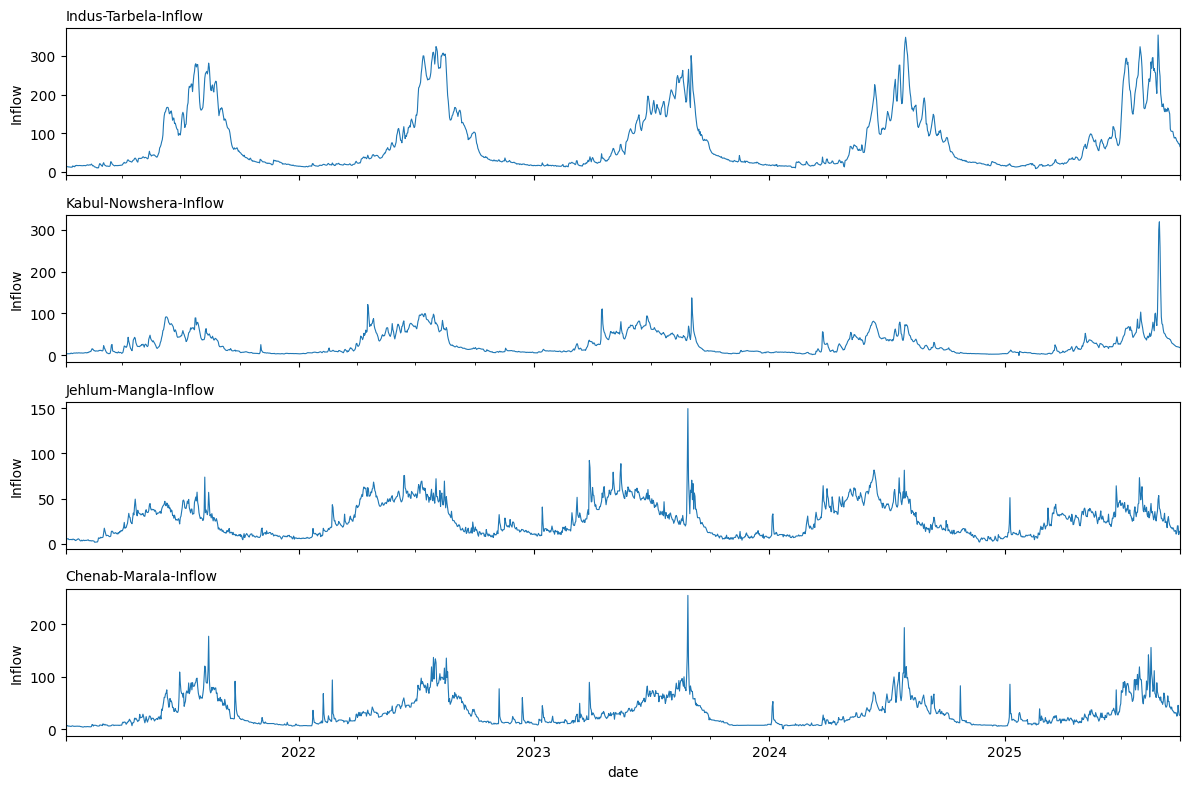

,Indus-Tarbela-Inflow,Kabul-Nowshera-Inflow,Jehlum-Mangla-Inflow,Chenab-Marala-Inflow
Year,,,,
2021,281.2,92.0,73.8,177.3
2022,323.9,121.4,75.6,136.9
2023,300.5,137.2,149.4,255.4
2024,348.0,81.6,81.6,193.8
2025,353.8,318.5,73.2,155.9


In [9]:
rivers = ['Indus-Tarbela-Inflow', 'Kabul-Nowshera-Inflow', 'Jehlum-Mangla-Inflow', 'Chenab-Marala-Inflow']
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, rivers):
    daily[c].plot(ax=ax, lw=0.8)
    ax.set_title(c, loc='left', fontsize=10); ax.set_ylabel('Inflow')
plt.tight_layout(); plt.show()

# Highest inflow of each river in each year
display(daily[rivers].groupby(daily.index.year).max().round(1).rename_axis('Year'))

## Step 3: What exactly do we predict?
- **Inputs (features):** today's values of all 8 columns, the last 2 days and the 3-day average of the river we forecast, and the month.
- **Output (answer):** the inflow of that river **tomorrow** (or 2, 3, 4, 5 days ahead).
- **Training data:** 2021–2023. **Test data:** 2024 to September 2025 (the models never see it while learning).
- **No leakage:** the inputs only use information up to today, and the answer is always in the future.

In [10]:
WINDOW = 7            # LSTM looks at the last 7 days
TRAIN_END_YEAR = 2023

def make_table(target, h):
    # One row per day: inputs from today (and the past), answer = inflow h days later
    X = daily.copy()
    X['target_lag1'] = daily[target].shift(1)            # yesterday
    X['target_lag2'] = daily[target].shift(2)            # 2 days ago
    X['target_avg3'] = daily[target].rolling(3).mean()   # average of the last 3 days
    X['month'] = X.index.month
    X['y'] = daily[target].shift(-h)                     # the answer: inflow h days ahead
    X['pos'] = np.arange(len(X))                         # row number (used by the LSTM)
    X = X.dropna()
    return X[X['pos'] >= WINDOW - 1]

def evaluate(name, y_true, pred):
    return {'Model': name, 'R2': r2_score(y_true, pred),
            'RMSE': mean_squared_error(y_true, pred) ** 0.5, 'MAE': mean_absolute_error(y_true, pred)}
print('Helper functions ready')

Helper functions ready


## Step 4: The models
| Model | Idea |
|---|---|
| Baseline | "Tomorrow will be the same as today". The simplest guess. Every model must beat this. |
| Linear Regression | Draws the best straight-line rule from the inputs |
| Random Forest | 300 decision trees; the answer is their average |
| XGBoost | Trees built one after another; each fixes the mistakes of the earlier ones |
| LSTM | Deep-learning model with memory; it reads the last 7 days |

**Scores (for numbers, not yes/no):**
- **R²:** how much of the up-and-down pattern the model catches (1 = perfect, 0 = no better than the average).
- **RMSE and MAE:** the average size of the mistake (smaller is better). RMSE punishes big mistakes more.

In [11]:
from xgboost import XGBRegressor
USE_LSTM = True

def lstm_predict(train, test):
    import tensorflow as tf
    from tensorflow.keras import layers
    tf.random.set_seed(42); np.random.seed(42)
    scaler = StandardScaler().fit(daily[daily.index.year <= TRAIN_END_YEAR])   # learn the scale from training years only
    scaled = scaler.transform(daily)
    ymean, ystd = train['y'].mean(), train['y'].std()
    make_seq = lambda rows: np.array([scaled[p - WINDOW + 1:p + 1] for p in rows['pos']])
    Xs_train, Xs_test = make_seq(train), make_seq(test)
    ys_train = ((train['y'] - ymean) / ystd).values
    model = tf.keras.Sequential([layers.Input(shape=(WINDOW, scaled.shape[1])),
                                 layers.LSTM(32), layers.Dropout(0.2), layers.Dense(1)])
    model.compile(optimizer='adam', loss='mse')
    stop = tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)   # stop when it starts memorising
    history = model.fit(Xs_train, ys_train, epochs=80, batch_size=32, validation_split=0.1,
                        callbacks=[stop], verbose=0)
    return model.predict(Xs_test, verbose=0).ravel() * ystd + ymean, history

def run_models(target, h=1, use_lstm=False):
    X = make_table(target, h)
    train, test = X[X.index.year <= TRAIN_END_YEAR], X[X.index.year > TRAIN_END_YEAR]
    feats = [c for c in X.columns if c not in ('y', 'pos')]
    preds = {'Baseline (same as today)': test[target].values}
    preds['Linear Regression'] = LinearRegression().fit(train[feats], train['y']).predict(test[feats])
    preds['Random Forest'] = RandomForestRegressor(300, random_state=42, n_jobs=-1).fit(train[feats], train['y']).predict(test[feats])
    xgb = XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8,
                       colsample_bytree=0.8, random_state=42).fit(train[feats], train['y'])
    preds['XGBoost'] = xgb.predict(test[feats])
    history = None
    if use_lstm:
        preds['LSTM'], history = lstm_predict(train, test)
    table = pd.DataFrame([evaluate(n, test['y'], p) for n, p in preds.items()]).set_index('Model').round(3)
    return dict(table=table, preds=preds, train=train, test=test, xgb=xgb, feats=feats, history=history)
print('Models ready')

Models ready


## Step 5: Forecast tomorrow's inflow (1 day ahead)

In [12]:
TARGETS = {'Kabul River at Nowshera': 'Kabul-Nowshera-Inflow',
           'Chenab River at Marala': 'Chenab-Marala-Inflow'}
out = {}
for name, col in TARGETS.items():
    out[name] = run_models(col, h=1, use_lstm=USE_LSTM)
    print(f'\n=== {name}: forecast for tomorrow ===')
    print('Training days:', len(out[name]['train']), '| Test days:', len(out[name]['test']))
    display(out[name]['table'])

2026-10-19 06:08:36.957038: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



=== Kabul River at Nowshera: forecast for tomorrow ===
Training days: 1086 | Test days: 638


,R2,RMSE,MAE
Model,,,
Baseline (same as today),0.902,9.204,3.213
Linear Regression,0.925,8.058,3.369
Random Forest,0.711,15.831,3.975
XGBoost,0.705,15.985,4.406
LSTM,0.566,19.408,8.210



=== Chenab River at Marala: forecast for tomorrow ===
Training days: 1086 | Test days: 638


,R2,RMSE,MAE
Model,,,
Baseline (same as today),0.819,11.489,5.308
Linear Regression,0.847,10.543,5.657
Random Forest,0.835,10.952,5.893
XGBoost,0.831,11.113,6.456
LSTM,0.835,10.982,6.451


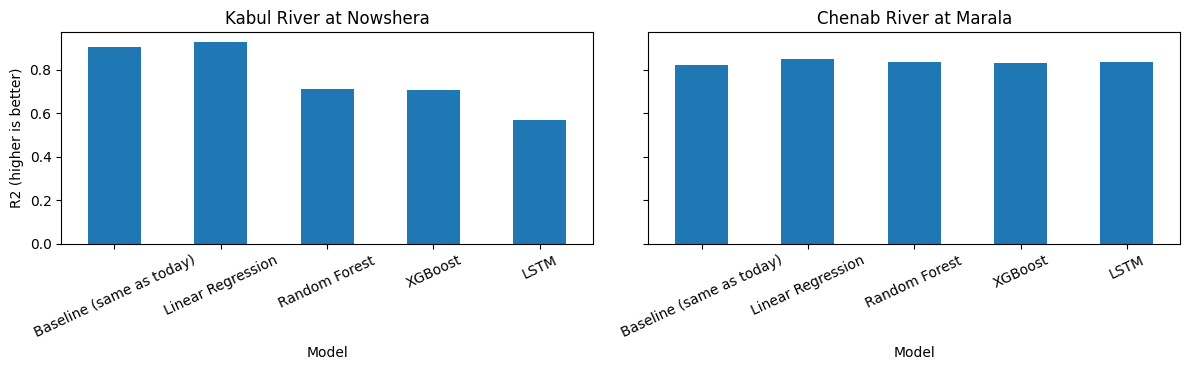

In [13]:
# Results as a chart: R2 (higher is better)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, o) in zip(axes, out.items()):
    o['table']['R2'].plot(kind='bar', ax=ax, color='tab:blue', title=name)
    ax.set_ylabel('R2 (higher is better)'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

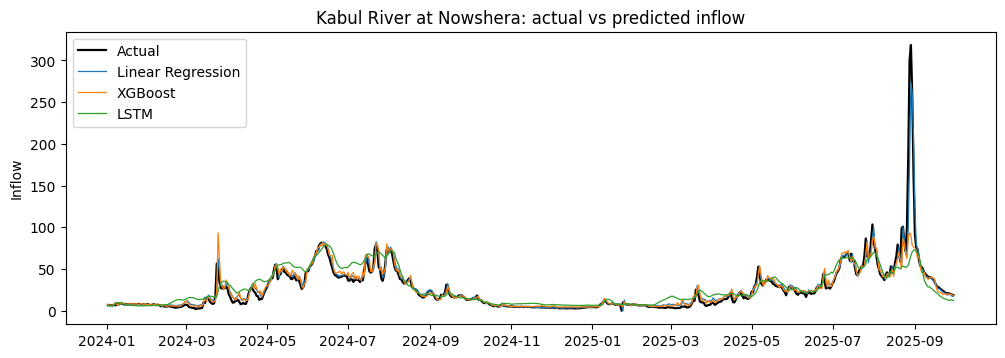

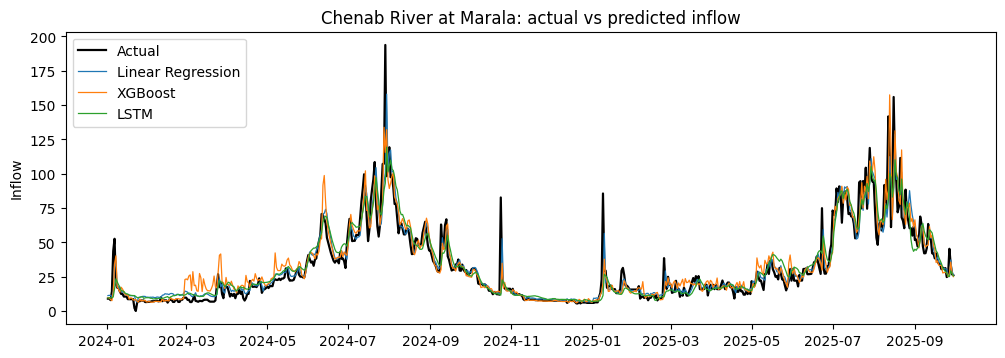

In [14]:
# Actual vs predicted over the whole test period
for name, o in out.items():
    plt.figure(figsize=(12, 3.8))
    when = o['test'].index + pd.Timedelta(days=1)          # the day that is being predicted
    plt.plot(when, o['test']['y'], 'k', lw=1.6, label='Actual')
    for m in ['Linear Regression', 'XGBoost', 'LSTM']:
        if m in o['preds']:
            plt.plot(when, o['preds'][m], lw=0.9, label=m)
    plt.title(f'{name}: actual vs predicted inflow'); plt.ylabel('Inflow'); plt.legend(); plt.show()

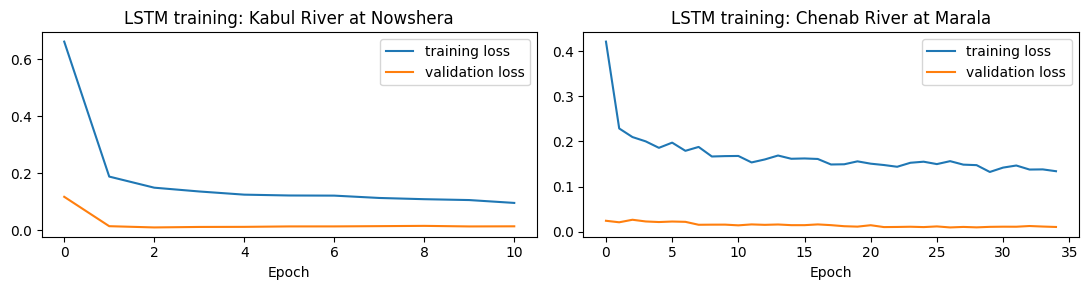

In [15]:
# LSTM training curve: if the validation line goes up while training keeps going down, the model is memorising
if USE_LSTM:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax, (name, o) in zip(axes, out.items()):
        ax.plot(o['history'].history['loss'], label='training loss')
        ax.plot(o['history'].history['val_loss'], label='validation loss')
        ax.set_title(f'LSTM training: {name}'); ax.set_xlabel('Epoch'); ax.legend()
    plt.tight_layout(); plt.show()

## Step 6: The big flood of August 2025 (Kabul River)
The Kabul River had a very big peak in August 2025 – much **higher than anything in the training years (2021–2023)**.
Can the models predict a flood that is bigger than anything they have seen before?

Highest inflow in the TRAINING years : 137.2
Highest inflow in the TEST period    : 318.5


,Highest predicted value
Baseline (same as today),318.5
Linear Regression,273.8
Random Forest,96.9
XGBoost,93.3
LSTM,79.0


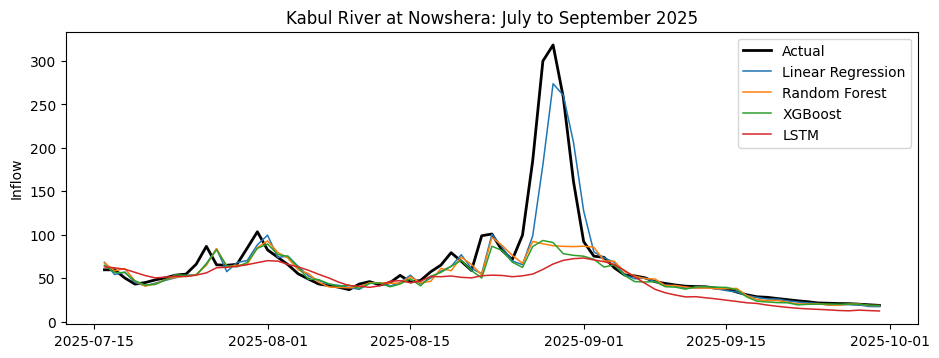

In [16]:
o = out['Kabul River at Nowshera']
print('Highest inflow in the TRAINING years :', round(o['train']['y'].max(), 1))
print('Highest inflow in the TEST period    :', round(o['test']['y'].max(), 1))
display(pd.DataFrame({m: [p.max()] for m, p in o['preds'].items()}, index=['Highest predicted value']).T.round(1))

mask = (o['test'].index >= '2025-07-15')
when = o['test'].index[mask] + pd.Timedelta(days=1)
plt.figure(figsize=(11, 3.8))
plt.plot(when, o['test']['y'][mask], 'k', lw=2, label='Actual')
for m in ['Linear Regression', 'Random Forest', 'XGBoost', 'LSTM']:
    if m in o['preds']:
        plt.plot(when, o['preds'][m][mask], lw=1.1, label=m)
plt.title('Kabul River at Nowshera: July to September 2025'); plt.ylabel('Inflow'); plt.legend(); plt.show()

## Step 7: How far ahead can we forecast? (1 to 5 days)
Paper 8 forecast 1 to 5 days ahead. We do the same and watch how the score drops.

,River,Days ahead,Baseline (same as today),Linear Regression,Random Forest,XGBoost
0,Kabul River at Nowshera,1,0.902,0.925,0.711,0.705
1,Kabul River at Nowshera,2,0.697,0.749,0.631,0.602
2,Kabul River at Nowshera,3,0.497,0.595,0.558,0.517
3,Kabul River at Nowshera,4,0.365,0.503,0.507,0.452
4,Kabul River at Nowshera,5,0.298,0.457,0.462,0.413
5,Chenab River at Marala,1,0.819,0.847,0.835,0.831
6,Chenab River at Marala,2,0.731,0.774,0.783,0.793
7,Chenab River at Marala,3,0.698,0.731,0.707,0.724
8,Chenab River at Marala,4,0.659,0.696,0.680,0.672
9,Chenab River at Marala,5,0.620,0.671,0.662,0.667


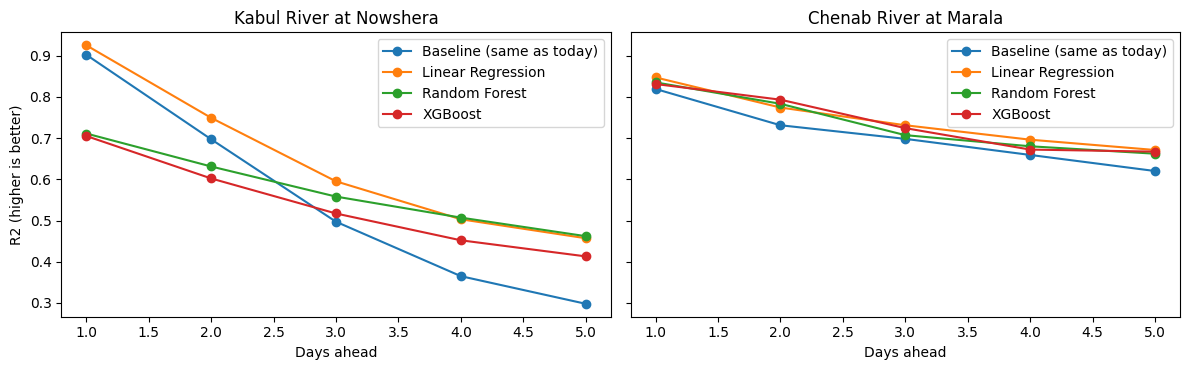

In [17]:
rows = []
for name, col in TARGETS.items():
    for h in range(1, 6):
        r = run_models(col, h=h, use_lstm=False)['table']['R2']
        rows.append({'River': name, 'Days ahead': h, 'Baseline (same as today)': r['Baseline (same as today)'],
                     'Linear Regression': r['Linear Regression'], 'Random Forest': r['Random Forest'], 'XGBoost': r['XGBoost']})
horizon = pd.DataFrame(rows)
display(horizon.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, g) in zip(axes, horizon.groupby('River', sort=False)):
    g.set_index('Days ahead').drop(columns='River').plot(ax=ax, marker='o', title=name)
    ax.set_ylabel('R2 (higher is better)')
plt.tight_layout(); plt.show()

## Step 8: Which inputs did XGBoost use the most?
(`target_lag1` = yesterday's inflow, `target_lag2` = 2 days ago, `target_avg3` = 3-day average of the river we forecast.)

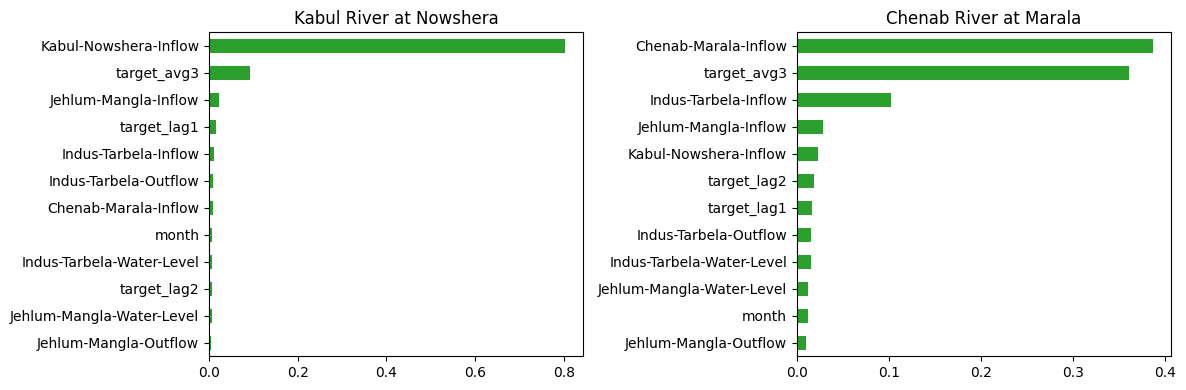

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, o) in zip(axes, out.items()):
    pd.Series(o['xgb'].feature_importances_, index=o['feats']).sort_values().plot(kind='barh', ax=ax, color='tab:green', title=name)
plt.tight_layout(); plt.show()

## Conclusion
- We used daily river and dam data of Pakistan (2021 to September 2025) to forecast the inflow of the **Kabul River (Nowshera)** and the **Chenab River (Marala)**.
- "Tomorrow = today" is already a strong guess for 1 day ahead. The models improve on it only a little, and the forecast gets worse as we look 3 to 5 days ahead (like Paper 8).
- Tree models (Random Forest, XGBoost) **cannot predict values bigger than anything they saw in training**. This is why they missed the very big Kabul River peak of August 2025 (Step 6).
- **Limitations:** only river and dam data (no rain, no satellite), daily values only, only 4 river points, and the year of each date had to be rebuilt (the file has no year).
- **Link to my thesis:** river data alone only shows the flood **after** water has already started to rise. My thesis adds **satellite rainfall, weather and terrain data** to warn **hours earlier**, for flash floods in **KP and Balochistan**.